In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier
from helper import *
from plots import *
from timeit import default_timer as timer
import random
from scipy.stats import randint as sp_randint
from scipy.stats import uniform as sp_uniform
from skopt.space import Integer, Real, Categorical
from skopt import BayesSearchCV

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

In [4]:
df = pd.read_csv("adult.csv")

## 1. Предобработка

In [5]:
df_preprocessed = df.copy()

df_preprocessed['workclass'] = df_preprocessed['workclass'].replace('?', np.nan)
df_preprocessed['occupation'] = df_preprocessed['occupation'].replace('?', np.nan)
df_preprocessed['native-country'] = df_preprocessed['native-country'].replace('?', np.nan)

df_preprocessed = df_preprocessed.drop(columns=['educational-num'])

df_preprocessed['income'] = np.where(df_preprocessed['income'] == '>50K', 1, 0)

In [6]:
X, y = divide_data(df_preprocessed, 'income')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=SEED, 
    stratify=y  
)


categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship','race', 'gender', 'native-country']
numeric_cols = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']
most_frequent_cat_cols = ['workclass', 'occupation', 'native-country']


In [ ]:
category_orders = [
    # workclass
    ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 
     'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay'],
    
    # education
    ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 
     'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 
     'Masters', 'Preschool', 'Prof-school', 'Some-college'],
     
    # marital-status
    ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 
     'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed'],
     
    # occupation
    ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 
     'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 
     'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 
     'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 
     'Transport-moving'],
     
    # relationship
    ['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 
     'Unmarried', 'Wife'],
     
    # race
    ['Amer-Indian-Eskimo', 'Asian-Pac-Islander', 'Black', 'Other', 'White'],
    
    # sex
    ['Male', 'Female'],
    
    # native-country
    ['Cambodia', 'Canada', 'China', 'Columbia', 'Cuba', 
     'Dominican-Republic', 'Ecuador', 'El-Salvador', 'England', 
     'France', 'Germany', 'Greece', 'Guatemala', 'Haiti', 
     'Holand-Netherlands', 'Honduras', 'Hong', 'Hungary', 'India', 
     'Iran', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Laos', 
     'Mexico', 'Nicaragua', 'Outlying-US(Guam-USVI-etc)', 'Peru', 
     'Philippines', 'Poland', 'Portugal', 'Puerto-Rico', 'Scotland', 
     'South', 'Taiwan', 'Thailand', 'Trinadad&Tobago', 'United-States', 
     'Vietnam', 'Yugoslavia']
]


preprocessor = Pipeline([
    ('nan_remover', ColumnTransformer(
        [
            ('most_frequent_cat', SimpleImputer(strategy='most_frequent'), most_frequent_cat_cols),
        ],
        remainder='passthrough',  
        verbose_feature_names_out=False  
    )),
    
    ('transformations', ColumnTransformer(
        [('encoder', TargetEncoder(categories=category_orders), categorical_cols)],
        remainder='passthrough',  
        verbose_feature_names_out=False
    ))
])

preprocessor.set_output(transform="pandas")

,steps,"[('nan_remover', ...), ('transformations', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('most_frequent_cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [8]:
base_model = ('LGBMClassifier', LGBMClassifier(random_state=SEED))

In [9]:
preprocessor.steps.append(base_model)
pipeline = preprocessor

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000960 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1063
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685


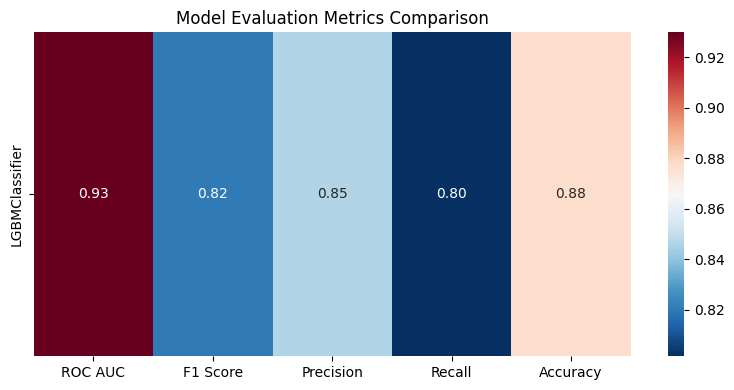

In [10]:
initial_metrics = train_evaluate_models(
    models=[('LGBMClassifier', pipeline)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)

In [11]:
initial_metrics

,ROC AUC,F1 Score,Precision,Recall,Accuracy
LGBMClassifier,0.929776,0.820306,0.846238,0.801627,0.877265


## 2. Подбор гиперпараметров

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### 2.1 Grid Search

In [13]:
param_grid = {
    # Контроль сложности модели и переобучения
    "LGBMClassifier__num_leaves": [7, 15, 31],  # Максимальное количество листьев в дереве (влияет на сложность модели)
    "LGBMClassifier__max_depth": [3, 5, 7],     # Максимальная глубина дерева (ограничивает сложность)
    "LGBMClassifier__min_child_samples": [5, 10, 20],  # Минимальное количество данных в листе (контроль переобучения)
    
    # Скорость обучения и количество итераций бустинга
    "LGBMClassifier__learning_rate": [0.01, 0.05, 0.1],  # Скорость обучения (шаг градиентного спуска)
    "LGBMClassifier__n_estimators": [10, 20, 30, 40, 50, 100, 200],  # Количество деревьев в ансамбле
    
    # Регуляризация
    # "LGBMClassifier__reg_alpha": [0, 0.1, 1],   # L1-регуляризация (лассо)
    # "LGBMClassifier__reg_lambda": [0, 0.1, 1],  # L2-регуляризация (ридж)
    
    # Сэмплирование признаков
    # "LGBMClassifier__feature_fraction": [0.7, 0.9, 1.0],  # Доля признаков для использования при построении каждого дерева
    # "LGBMClassifier__bagging_fraction": [0.7, 0.9],       # Доля данных для использования в каждом бустинговом раунде
    # "LGBMClassifier__bagging_freq": [0, 1],               # Частота бэггинга (0 - отключен)
    
    # # Другие параметры
    # "LGBMClassifier__subsample": [0.8, 1.0],               # Доля случайных примеров для обучения каждого дерева
    # "LGBMClassifier__colsample_bytree": [0.7, 0.9, 1.0],   # Доля признаков для каждого дерева
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    verbose=3
)

In [14]:
grid_search_start = timer()
grid_search.fit(X_train, y_train)
grid_search_end = timer()

Fitting 5 folds for each of 567 candidates, totalling 2835 fits
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002474 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1032
[LightGBM] [Info] Number of data points in the train set: 31258, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239267 -> initscore=-1.156704
[LightGBM] [Info] Start training from score -1.156704
[CV 1/5] END LGBMClassifier__learning_rate=0.01, LGBMClassifier__max_depth=3, LGBMClassifier__min_child_samples=5, LGBMClassifier__n_estimators=10, LGBMClassifier__num_leaves=7;, score=0.878 total time=   0.2s
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002405 seconds.
You can set `force_col_wise=true` to remove the overhead.
[

In [15]:
print(f"Total time: {grid_search_end - grid_search_start:.2f} seconds")

Total time: 1171.68 seconds


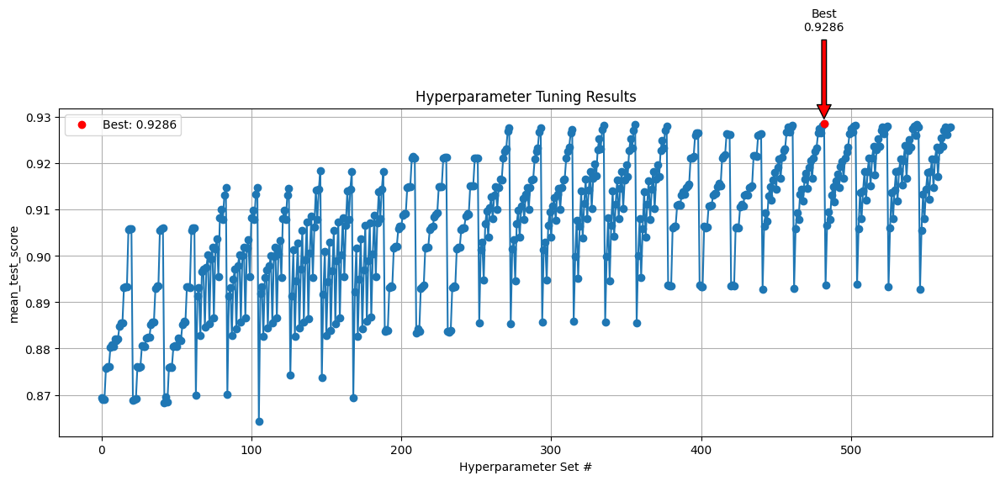

In [16]:
data = plot_hyperparam_search_results(grid_search.cv_results_, xtick_step=100)

In [17]:
grid_search.best_params_

{'LGBMClassifier__learning_rate': 0.1,
 'LGBMClassifier__max_depth': 5,
 'LGBMClassifier__min_child_samples': 10,
 'LGBMClassifier__n_estimators': 200,
 'LGBMClassifier__num_leaves': 31}

In [18]:
grid_search_best_model = grid_search.best_estimator_

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003603 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1066
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

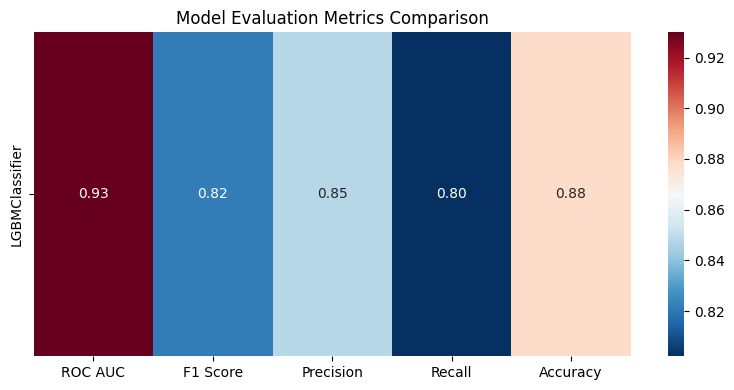

In [19]:
grid_search_metrics = train_evaluate_models(
    models=[('LGBMClassifier', grid_search_best_model)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)

In [20]:
grid_search_metrics

,ROC AUC,F1 Score,Precision,Recall,Accuracy
LGBMClassifier,0.929969,0.821264,0.847943,0.802165,0.878084


(<Figure size 800x400 with 2 Axes>,
                  ROC AUC  F1 Score  Precision    Recall  Accuracy
 LGBMClassifier  0.000194  0.000957   0.001706  0.000538  0.000819)

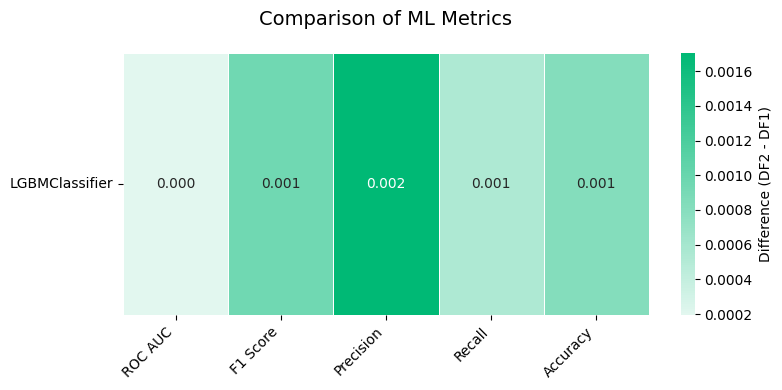

In [21]:
compare_metrics_heatmap(initial_metrics, grid_search_metrics)

### 2.2 Randomized search

In [22]:
param_dist = {
    "LGBMClassifier__num_leaves": sp_randint(7, 32), 
    "LGBMClassifier__max_depth": sp_randint(3, 8), 
    "LGBMClassifier__min_child_samples": sp_randint(5, 10, 20),
    
    "LGBMClassifier__learning_rate": sp_uniform(0.01, 0.1),
    "LGBMClassifier__n_estimators": sp_randint(10, 200),  
}

In [23]:
randomized_search = RandomizedSearchCV(
    random_state=SEED,
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=100,
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    verbose=3
)

In [24]:
randomized_search_start = timer()
randomized_search.fit(X_train, y_train)
randomized_search_end = timer()

Fitting 5 folds for each of 100 candidates, totalling 500 fits
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001621 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1031
[LightGBM] [Info] Number of data points in the train set: 31258, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239267 -> initscore=-1.156704
[LightGBM] [Info] Start training from score -1.156704
[CV 1/5] END LGBMClassifier__learning_rate=0.047454011884736254, LGBMClassifier__max_depth=7, LGBMClassifier__min_child_samples=27, LGBMClassifier__n_estimators=81, LGBMClassifier__num_leaves=27;, score=0.926 total time=   0.4s
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing 

In [25]:
print(f"Total time: {randomized_search_end - randomized_search_start:.2f} seconds")

Total time: 244.22 seconds


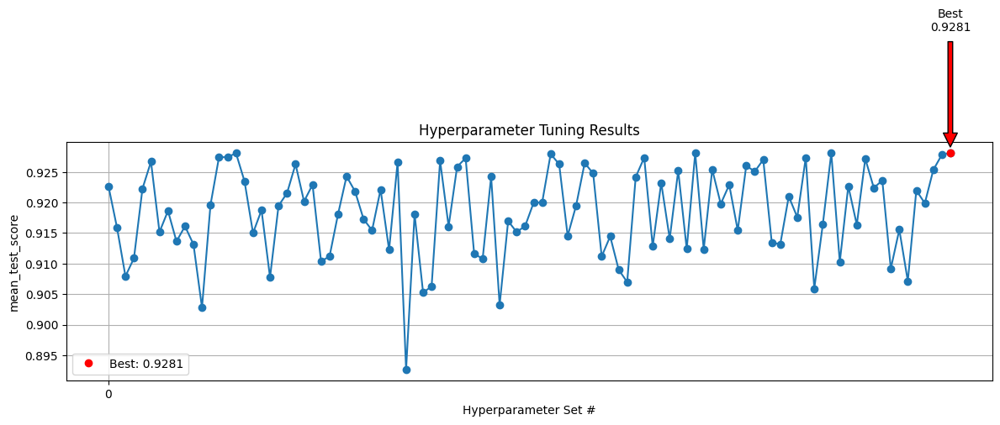

In [26]:
data = plot_hyperparam_search_results(randomized_search.cv_results_, xtick_step=100)

In [27]:
randomized_search.best_params_

{'LGBMClassifier__learning_rate': np.float64(0.0967116607209722),
 'LGBMClassifier__max_depth': 7,
 'LGBMClassifier__min_child_samples': 28,
 'LGBMClassifier__n_estimators': 122,
 'LGBMClassifier__num_leaves': 29}

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002842 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1064
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


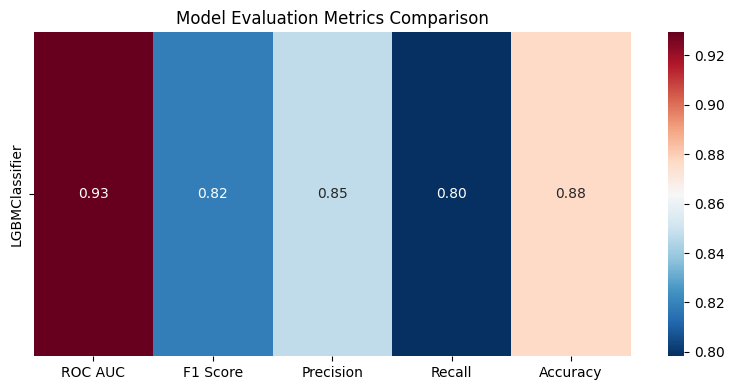

In [28]:
randomized_search_metrics = train_evaluate_models(
    models=[('LGBMClassifier', randomized_search.best_estimator_)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)

In [29]:
randomized_search_metrics

,ROC AUC,F1 Score,Precision,Recall,Accuracy
LGBMClassifier,0.929311,0.818419,0.847366,0.798212,0.876753


(<Figure size 800x400 with 2 Axes>,
                  ROC AUC  F1 Score  Precision    Recall  Accuracy
 LGBMClassifier -0.000465 -0.001887   0.001128 -0.003414 -0.000512)

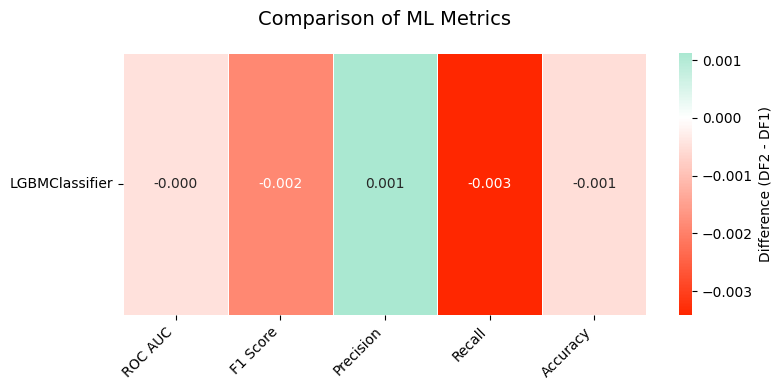

In [30]:
compare_metrics_heatmap(initial_metrics, randomized_search_metrics)

### 2.3 Bayes Search

In [31]:
param_bayes = {
    "LGBMClassifier__num_leaves": Integer(7, 31), 
    "LGBMClassifier__max_depth": Integer(3, 7),  
    "LGBMClassifier__min_child_samples": Integer(5, 20), 
    
    # Логарифмическая шкала используется потому что:
    # 1) learning_rate обычно варьируется в порядках величины (0.001-0.1)
    # 2) Логарифмирование дает более равномерный поиск в широком диапазоне значений
    # 3) Разница между 0.01 и 0.02 часто значительнее, чем между 0.1 и 0.11
    "LGBMClassifier__learning_rate": Real(0.01, 0.1, prior='log-uniform'),
    
    "LGBMClassifier__n_estimators": Integer(10, 200), 
}

In [32]:
bayes_search = BayesSearchCV(
    random_state=SEED,
    estimator=pipeline,
    search_spaces=param_bayes,
    n_iter=100, 
    cv=cv,      
    scoring='roc_auc',  
    optimizer_kwargs={'base_estimator': 'GP'}, 
    verbose=3,
    n_jobs=1 
)

In [33]:
bayes_search_start = timer()
bayes_search.fit(X_train, y_train)
bayes_search_end = timer()

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002823 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1037
[LightGBM] [Info] Number of data points in the train set: 31258, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239267 -> initscore=-1.156704
[LightGBM] [Info] Start training from score -1.156704
[CV 1/5] END LGBMClassifier__learning_rate=0.02571011142608906, LGBMClassifier__max_depth=6, LGBMClassifier__min_child_samples=19, LGBMClassifier__n_estimators=70, LGBMClassifier__num_leaves=23;, score=0.920 total time=   0.4s
[LightGBM] [Info] Number of positive: 7479, number of negative: 23779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0

In [34]:
print(f"Total time: {bayes_search_end - bayes_search_start:.2f} seconds")

Total time: 572.71 seconds


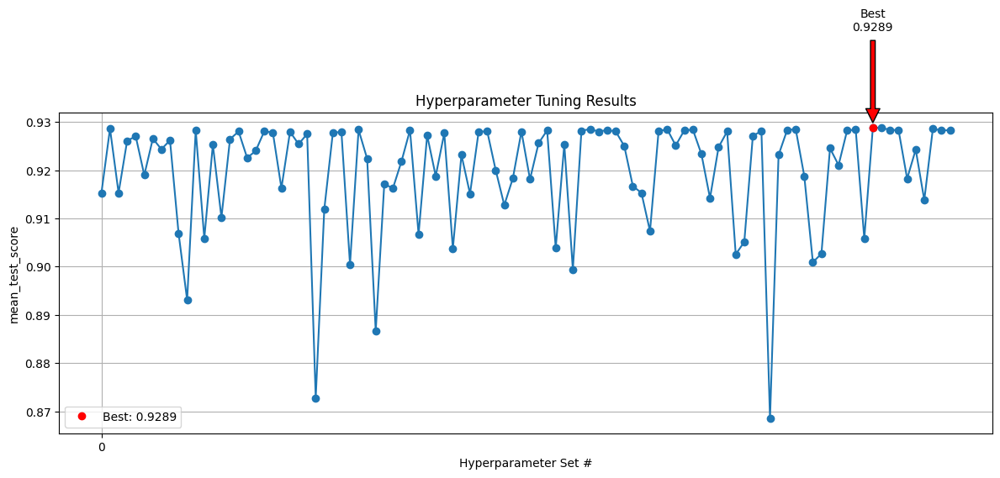

In [35]:
data = plot_hyperparam_search_results(bayes_search.cv_results_, xtick_step=100)

In [36]:
bayes_search.best_params_

OrderedDict([('LGBMClassifier__learning_rate', 0.1),
             ('LGBMClassifier__max_depth', 5),
             ('LGBMClassifier__min_child_samples', 5),
             ('LGBMClassifier__n_estimators', 190),
             ('LGBMClassifier__num_leaves', 26)])

[LightGBM] [Info] Number of positive: 9349, number of negative: 29724
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002790 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1062
[LightGBM] [Info] Number of data points in the train set: 39073, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239270 -> initscore=-1.156685
[LightGBM] [Info] Start training from score -1.156685
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

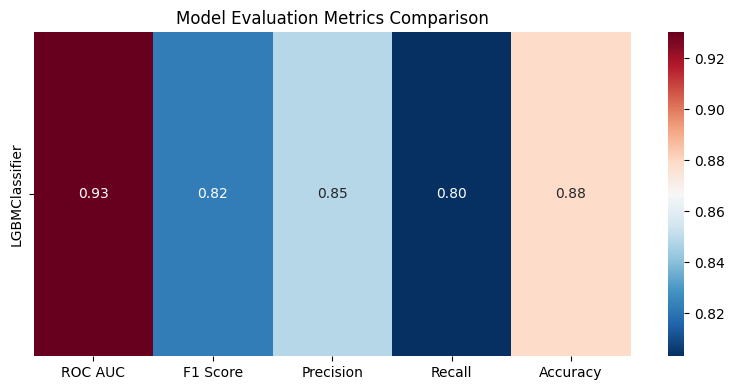

In [37]:
bayes_search_metrics = train_evaluate_models(
    models=[('LGBMClassifier', bayes_search.best_estimator_)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)

In [38]:
bayes_search_metrics

,ROC AUC,F1 Score,Precision,Recall,Accuracy
LGBMClassifier,0.930121,0.821985,0.848382,0.803021,0.878493


(<Figure size 800x400 with 2 Axes>,
                  ROC AUC  F1 Score  Precision    Recall  Accuracy
 LGBMClassifier  0.000345  0.001678   0.002144  0.001394  0.001228)

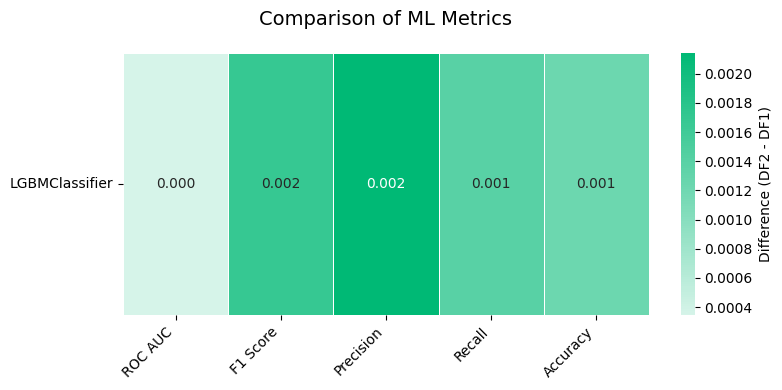

In [39]:
compare_metrics_heatmap(initial_metrics, bayes_search_metrics)

(<Figure size 800x400 with 2 Axes>,
                  ROC AUC  F1 Score  Precision    Recall  Accuracy
 LGBMClassifier  0.000151  0.000721   0.000438  0.000855  0.000409)

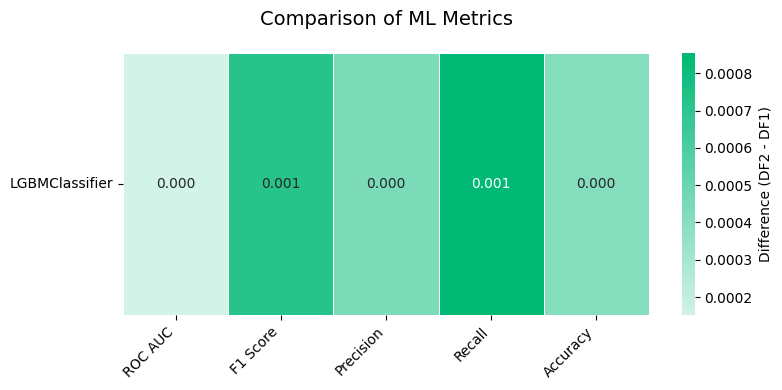

In [40]:
compare_metrics_heatmap(grid_search_metrics, bayes_search_metrics)

Вообще говоря, тестовая выборка нужна только затем, чтобы оценить результат финальной модели. На ее основе нельзя принимать никаких решений, для этого есть валидационная. Но я все же оставил тесты для разных методов для наглядности. Но даже по валидационной выборке Grid Search подобрал лучшие гиперпараметры, хоть и разница между подходами получилась небольшая. Также в Randomized Search и Bayes Search можно увеличить число итераций и возможно добиться лучших результатов. 